# 02 · Baselines on MIND-small

Three non-graph baselines that every later model has to beat:

| Model | Idea | Learns from |
|---|---|---|
| **random** | uniform random scores | nothing (sanity floor, expected AUC 0.5) |
| **popularity** | number of clicks in the training period | training-period clicks; unseen articles score 0 |
| **tfidf** | cosine between the user's mean history TF-IDF vector and each candidate | vocabulary/IDF from training-period articles; profile from the history snapshot |

**Protocol** (see README): TF-IDF settings are tuned on **validation** (fit on 9–13 Nov, scored on 14 Nov) using the *test-mix weighted* AUC, then frozen. All models are refit on 9–14 Nov and scored once on **test** (MIND dev, 15 Nov).

Results are produced by `uv run python -m recsys.experiments.run_baselines` (about 3 min), which writes `reports/baselines.csv` and `reports/tfidf_tuning.csv`. This notebook only reads and summarises them.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from recsys.paths import FIGURES_DIR, REPORTS_DIR

METRICS = ["auc", "mrr", "ndcg@5", "ndcg@10"]
MODELS = ["random", "popularity", "tfidf"]
MODEL_COLORS = {"random": "#2a78d6", "popularity": "#eb6834", "tfidf": "#1baf7a"}  # fixed slots 1-3
INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_SECONDARY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

results = pd.read_csv(REPORTS_DIR / "baselines.csv")
tuning = pd.read_csv(REPORTS_DIR / "tfidf_tuning.csv")

def table(split: str, segment: str) -> pd.DataFrame:
    rows = results[(results["split"] == split) & (results["segment"] == segment)]
    return rows.set_index("model").loc[MODELS, ["n_impressions", *METRICS]]

fmt = {"n_impressions": "{:,.0f}", **{m: "{:.4f}" for m in METRICS}}

## 1. Headline results

In [2]:
print("TEST (MIND dev, 15 Nov) - all impressions - final numbers")
display(table("test", "all").style.format(fmt).highlight_max(subset=METRICS, props="font-weight: bold"))

print("VALIDATION (14 Nov) - test-mix weighted - the tuning view")
display(table("validation", "test-mix weighted").style.format(fmt).highlight_max(subset=METRICS, props="font-weight: bold"))

TEST (MIND dev, 15 Nov) - all impressions - final numbers


,n_impressions,auc,mrr,ndcg@5,ndcg@10
model,,,,,
random,"73,152",0.5008,0.2189,0.2239,0.2868
popularity,"73,152",0.5318,0.2380,0.2457,0.3095
tfidf,"73,152",0.5778,0.2777,0.2963,0.3577


VALIDATION (14 Nov) - test-mix weighted - the tuning view


,n_impressions,auc,mrr,ndcg@5,ndcg@10
model,,,,,
random,"30,270",0.5021,0.2159,0.2169,0.2762
popularity,"30,270",0.5302,0.2295,0.2330,0.2960
tfidf,"30,270",0.5859,0.2878,0.3021,0.3572


**Interpretation:** On test, TF-IDF content similarity is clearly the strongest baseline (AUC 0.578, nDCG@10 0.358). Popularity is only a little above random (AUC 0.532 against 0.501). The validation test-mix view ranks the models in the same order with similar values, which suggests the reweighted row is a reasonable stand-in for test.

## 2. TF-IDF tuning (validation only)

Four configurations, selected by the test-mix weighted AUC. Test was not looked at during selection.

In [3]:
cols = ["ngram_range", "sublinear_tf", "test-mix weighted auc", "test-mix weighted ndcg@10", "user=new auc", "all auc"]
best_row = tuning["test-mix weighted auc"].idxmax()
(tuning[cols].style.format({c: "{:.4f}" for c in cols[2:]})
    .apply(lambda r: ["font-weight: bold" if r.name == best_row else "" for _ in r], axis=1))

,ngram_range,sublinear_tf,test-mix weighted auc,test-mix weighted ndcg@10,user=new auc,all auc
0,"(1, 1)",False,0.5854,0.3566,0.5842,0.5926
1,"(1, 1)",True,0.5859,0.3572,0.5849,0.5913
2,"(1, 2)",False,0.5854,0.3567,0.5837,0.5952
3,"(1, 2)",True,0.5854,0.3567,0.5839,0.5939


**Interpretation:** All four settings land within about 0.0005 AUC of each other, which is well below any meaningful difference. The selected setting (unigrams, sublinear TF) is effectively interchangeable with the defaults, so TF-IDF's performance comes from the idea itself, not from tuning.

## 3. Segment breakdowns

- **user=known/new**: whether the user had an impression in the training period.
- **article=seen/unseen**: each candidate list is restricted to seen (or unseen) articles and ranked again. These sub-lists are shorter, which inflates MRR and nDCG even for random scores, so **compare models within a segment, not across segments**. AUC is not affected by list length, so it is the cleanest metric for comparing segments.

In [4]:
SEGMENTS = ["all", "user=known", "user=new", "article=seen", "article=unseen"]

def segment_table(split: str, metric: str) -> pd.DataFrame:
    rows = results[results["split"] == split]
    return rows.pivot(index="segment", columns="model", values=metric).loc[
        [s for s in SEGMENTS + ["test-mix weighted"] if s in set(rows["segment"])], MODELS]

for split in ["test", "validation"]:
    n = results[(results["split"] == split) & (results["model"] == "random")].set_index("segment")["n_impressions"]
    for metric in ["auc", "ndcg@10"]:
        print(f"{split.upper()} - {metric}")
        display(segment_table(split, metric).assign(n_impressions=n).style.format({**{m: "{:.4f}" for m in MODELS}, "n_impressions": "{:,.0f}"}))

TEST - auc


model,random,popularity,tfidf,n_impressions
segment,,,,
all,0.5008,0.5318,0.5778,"73,152"
user=known,0.4992,0.5280,0.5818,"8,959"
user=new,0.5011,0.5323,0.5772,"64,193"
article=seen,0.5020,0.5359,0.5771,"59,233"
article=unseen,0.4957,0.5000,0.5773,"21,676"


TEST - ndcg@10


model,random,popularity,tfidf,n_impressions
segment,,,,
all,0.2868,0.3095,0.3577,"73,152"
user=known,0.2829,0.3054,0.3571,"8,959"
user=new,0.2873,0.3101,0.3578,"64,193"
article=seen,0.3171,0.3407,0.3853,"59,233"
article=unseen,0.4963,0.4980,0.5579,"21,676"


VALIDATION - auc


model,random,popularity,tfidf,n_impressions
segment,,,,
all,0.5012,0.5163,0.5913,"30,270"
user=known,0.5010,0.5131,0.5926,"25,312"
user=new,0.5022,0.5325,0.5849,"4,958"
article=seen,0.5022,0.5350,0.5830,"20,711"
article=unseen,0.5013,0.5000,0.6054,"14,036"
test-mix weighted,0.5021,0.5302,0.5859,"30,270"


VALIDATION - ndcg@10


model,random,popularity,tfidf,n_impressions
segment,,,,
all,0.2648,0.2780,0.3509,"30,270"
user=known,0.2622,0.2738,0.3495,"25,312"
user=new,0.2781,0.2990,0.3583,"4,958"
article=seen,0.2910,0.3135,0.3650,"20,711"
article=unseen,0.4793,0.4789,0.5636,"14,036"
test-mix weighted,0.2762,0.2960,0.3572,"30,270"


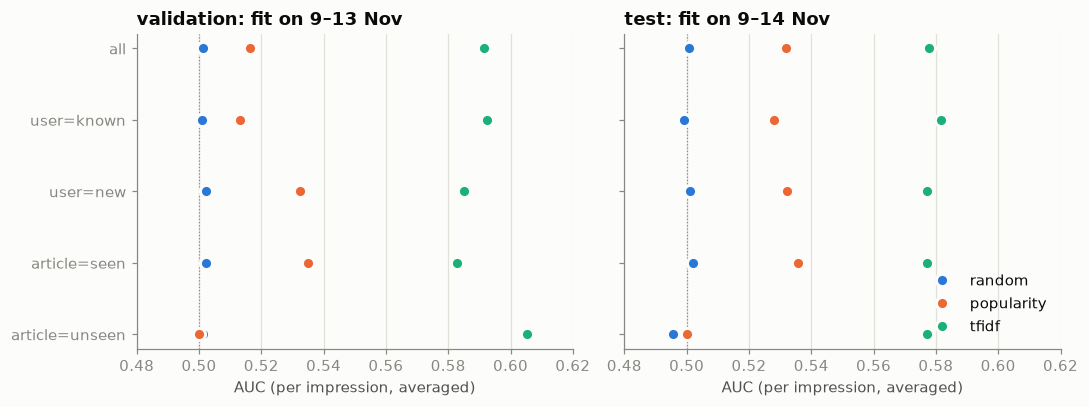

In [5]:
# Dot plot of AUC per segment: one row per segment, one dot per model, 0.5 = random.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, split in zip(axes, ["validation", "test"]):
    tbl = segment_table(split, "auc").reindex(SEGMENTS)
    y = range(len(tbl))[::-1]
    ax.axvline(0.5, color=MUTED, lw=0.8, ls=":")
    for model in MODELS:
        ax.plot(tbl[model], list(y), "o", ms=8, color=MODEL_COLORS[model], mec="#fcfcfb", mew=2, label=model)
    ax.set_yticks(list(y), tbl.index)
    ax.set_xlim(0.48, 0.62)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("AUC (per impression, averaged)")
    ax.set_title(f"{split}: fit on {'9–13' if split == 'validation' else '9–14'} Nov")
axes[1].legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_baseline_auc_by_segment.png")
plt.show()

**Interpretation:**

- **Popularity scores exactly 0.500 AUC on unseen articles.** It gives every unseen article 0, so it cannot rank them at all. Its small overall gain comes entirely from the seen part of each list.
- **TF-IDF works as well for new users as for known ones** (test AUC 0.577 vs 0.582). That's expected, because it builds each profile from the history snapshot, not from a user ID.
- **TF-IDF also handles unseen articles** (test AUC 0.577 on unseen vs 0.577 on seen). It needs only the article text, so new articles are ranked as well as familiar ones.
- **Known and new users differ very little for every baseline.** None of these models learns per-user parameters, so the user split mostly matters for models that will (for example ID embeddings or graph nodes).

## Takeaways for the next stages

- **The bar to beat on test is TF-IDF: AUC 0.578, MRR 0.278, nDCG@5 0.296, nDCG@10 0.358.** Any graph model that doesn't clear this on the test-mix validation view is not yet adding value.
- **Popularity as defined here (raw click counts over the training period) is weak.** News interest fades within hours, and every unseen article scores 0. A recency-aware popularity score (e.g. clicks in the last few hours, or CTR) would be a much stronger non-personalised baseline and is worth adding as a feature later.
- **Unseen articles and new users are where graph models must not regress.** Article–entity and article–category edges plus history-based (inductive) user representations should keep the unseen and new-user segments at or above TF-IDF.
- **Tuning margins this small are noise.** Differences of a few thousandths of AUC on validation should not drive decisions. Later stages should report variation across seeds or bootstrap confidence intervals before claiming improvements.